In [1]:
# Import libraries required for data analysis and linear regression

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [2]:
# Load the dataset from the current folder

df = pd.read_csv("food-texture.csv")

# Display the first five rows
print(df.head())

# Display the number of rows and columns
print("\nDataset shape:", df.shape)

  Unnamed: 0   Oil  Density  Crispy  Fracture  Hardness
0       B110  16.5     2955      10        23        97
1       B136  17.7     2660      14         9       139
2       B171  16.2     2870      12        17       143
3       B192  16.7     2920      10        31        95
4       B225  16.3     2975      11        26       143

Dataset shape: (50, 6)


In [3]:
# Display column names and data types
print("Column names:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Display statistical information
print("\nStatistical summary:")
print(df.describe())

Column names:
Index(['Unnamed: 0', 'Oil', 'Density', 'Crispy', 'Fracture', 'Hardness'], dtype='object')

Data types:
Unnamed: 0     object
Oil           float64
Density         int64
Crispy          int64
Fracture        int64
Hardness        int64
dtype: object

Missing values:
Unnamed: 0    0
Oil           0
Density       0
Crispy        0
Fracture      0
Hardness      0
dtype: int64

Statistical summary:
             Oil     Density     Crispy   Fracture    Hardness
count  50.000000    50.00000  50.000000  50.000000   50.000000
mean   17.202000  2857.60000  11.520000  20.860000  128.180000
std     1.592007   124.49998   1.775571   5.466073   31.127578
min    13.700000  2570.00000   7.000000   9.000000   63.000000
25%    16.300000  2772.50000  10.000000  17.000000  107.250000
50%    16.900000  2867.50000  12.000000  21.000000  126.000000
75%    18.100000  2945.00000  13.000000  25.000000  143.750000
max    21.200000  3125.00000  15.000000  33.000000  192.000000


In [4]:
# Remove the sample ID because it is not a useful predictor

df = df.drop(columns=["Unnamed: 0"])

# Display the remaining columns
print(df.columns)

Index(['Oil', 'Density', 'Crispy', 'Fracture', 'Hardness'], dtype='object')


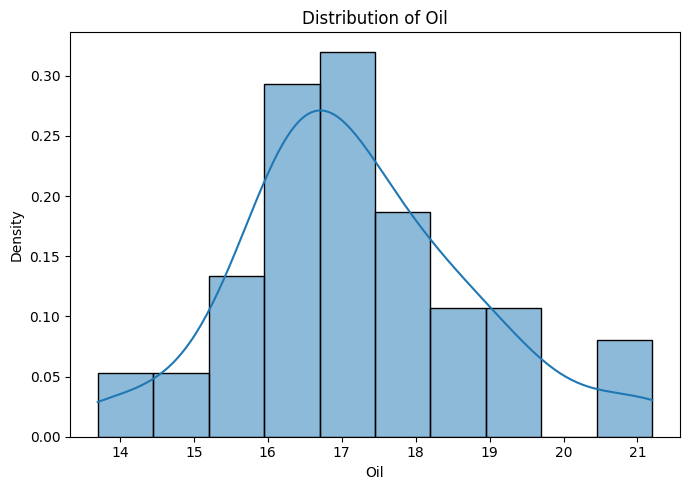

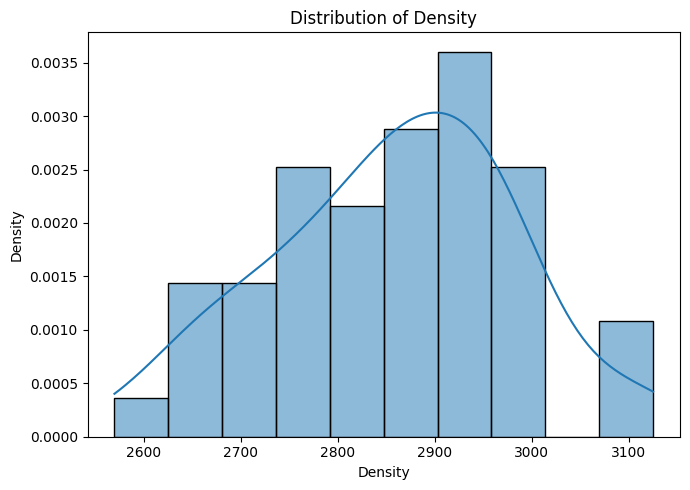

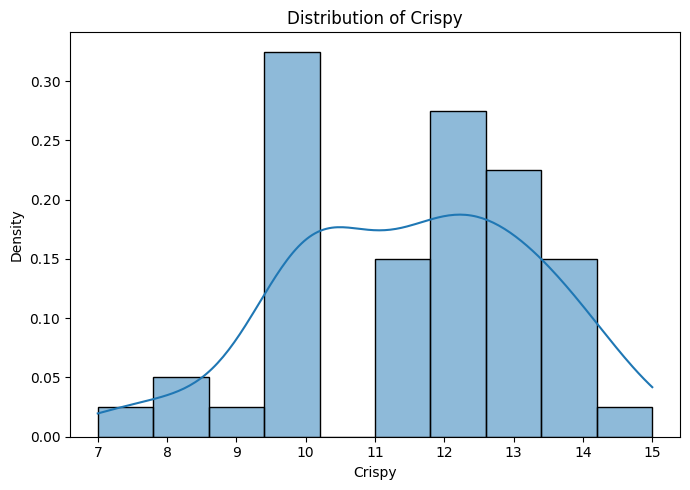

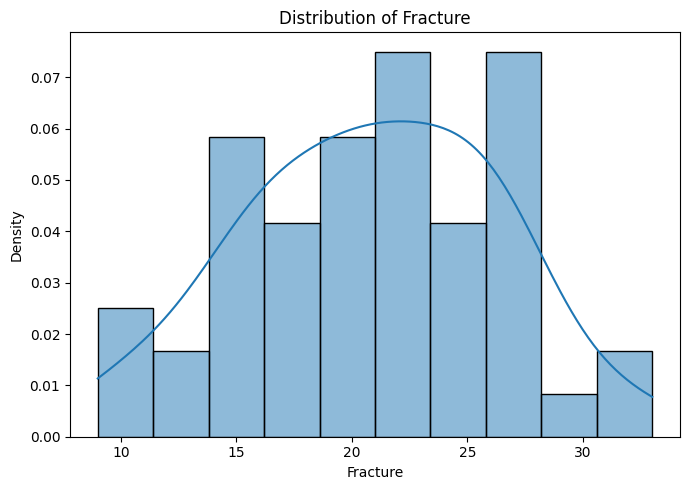

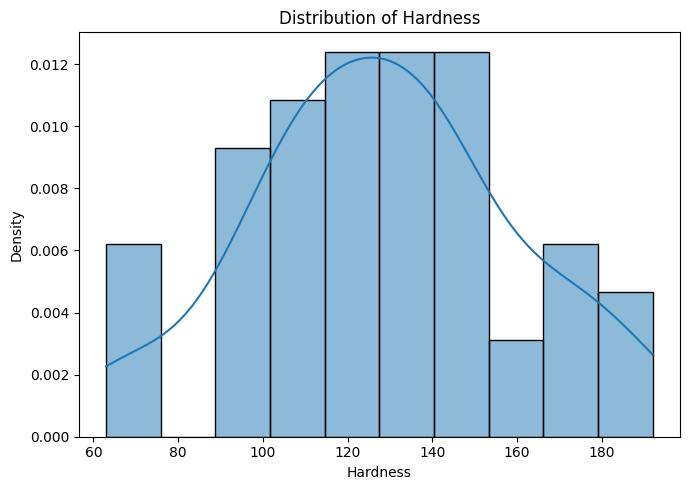

In [5]:
# Plot a histogram with a KDE curve for each numerical feature

for column in df.columns:

    plt.figure(figsize=(7, 5))

    # Histogram shows the distribution of values
    # KDE estimates the smooth probability density curve
    sns.histplot(data=df, x=column, bins=10,
                 kde=True, stat="density")

    plt.title("Distribution of " + column)
    plt.xlabel(column)
    plt.ylabel("Density")

    plt.tight_layout()
    plt.show()

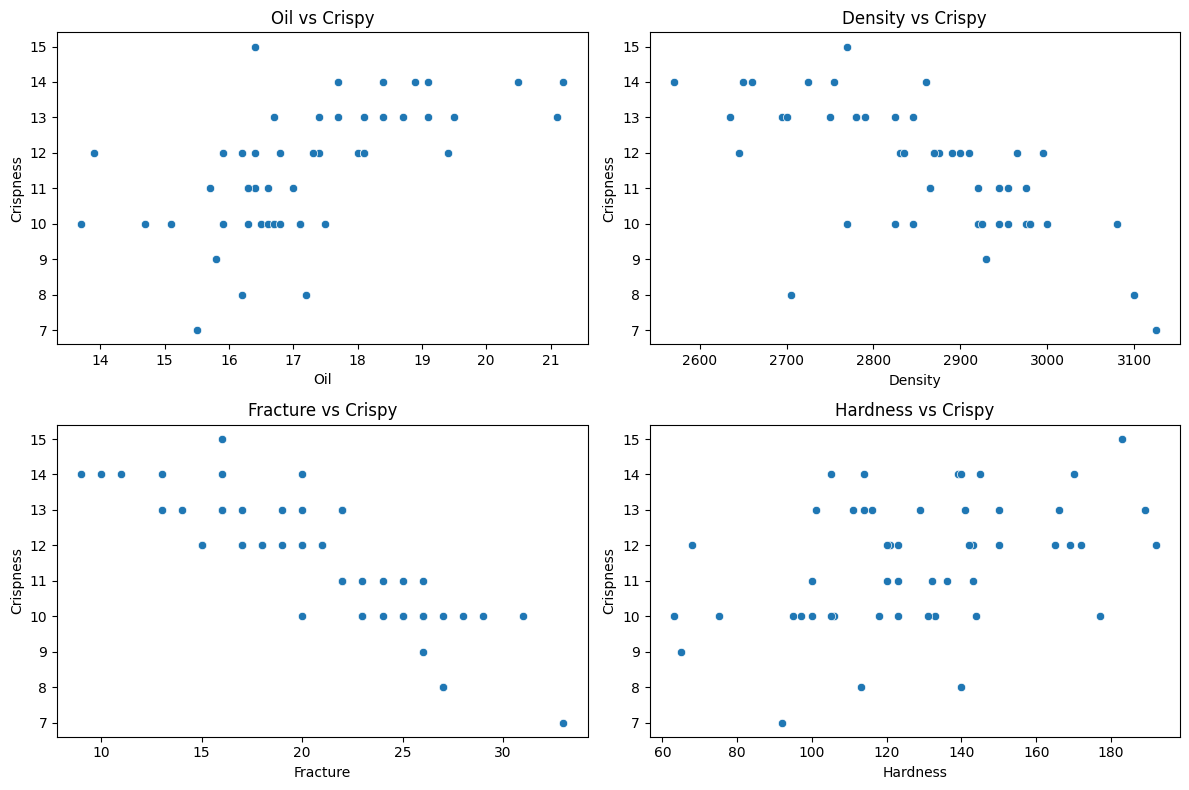

In [6]:
# Plot the relationship between each input feature and Crispy

features = ["Oil", "Density", "Fracture", "Hardness"]

# Create four subplots in 2 rows and 2 columns
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, column in enumerate(features):

    # Find the row and column for each subplot
    row = i // 2
    col = i % 2

    # Plot the input feature against Crispy
    sns.scatterplot(data=df, x=column, y="Crispy",
                    ax=axes[row, col])

    axes[row, col].set_title(column + " vs Crispy")
    axes[row, col].set_xlabel(column)
    axes[row, col].set_ylabel("Crispness")

plt.tight_layout()
plt.show()

               Oil   Density    Crispy  Fracture  Hardness
Oil       1.000000 -0.750024  0.593086 -0.533739 -0.096045
Density  -0.750024  1.000000 -0.670946  0.572132  0.107937
Crispy    0.593086 -0.670946  1.000000 -0.843965  0.411093
Fracture -0.533739  0.572132 -0.843965  1.000000 -0.373358
Hardness -0.096045  0.107937  0.411093 -0.373358  1.000000


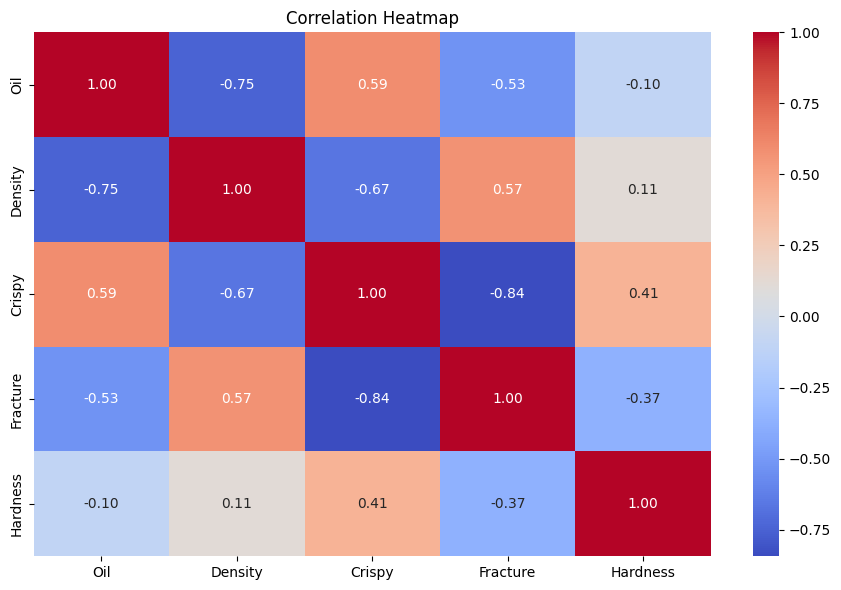

In [7]:
# Calculate correlations between numerical columns
correlation = df.corr()

# Display correlation values
print(correlation)

# Plot the correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(correlation, annot=True,
            cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [8]:
# Select only two input features
X2 = df[["Fracture", "Density"]]

# Select the target variable
y2 = df["Crispy"]

# Display the input and target data
print("Input features:")
print(X2.head())

print("\nTarget variable:")
print(y2.head())

print("\nInput shape:", X2.shape)
print("Target shape:", y2.shape)

Input features:
   Fracture  Density
0        23     2955
1         9     2660
2        17     2870
3        31     2920
4        26     2975

Target variable:
0    10
1    14
2    12
3    10
4    11
Name: Crispy, dtype: int64

Input shape: (50, 2)
Target shape: (50,)


In [9]:
# Use 80% of the data for training and 20% for testing

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

# Display the dimensions of each set
print("Training input:", X2_train.shape)
print("Testing input:", X2_test.shape)

print("Training target:", y2_train.shape)
print("Testing target:", y2_test.shape)

Training input: (40, 2)
Testing input: (10, 2)
Training target: (40,)
Testing target: (10,)


In [10]:
# Create the multiple linear regression model
model2 = LinearRegression()

# Train the model using the two input features
model2.fit(X2_train, y2_train)

print("2-feature Linear Regression model trained successfully")

2-feature Linear Regression model trained successfully


In [11]:
# Predict crispness for the testing data
y2_pred = model2.predict(X2_test)

# Compare actual and predicted values
results = pd.DataFrame({
    "Actual Crispy": y2_test.values,
    "Predicted Crispy": y2_pred
})

print(results)

   Actual Crispy  Predicted Crispy
0             12         11.614389
1             10          9.979362
2             10         10.293074
3             11         10.597421
4             12         12.337019
5             13         13.238382
6             10         10.314117
7             12         12.847171
8              7          7.848553
9             14         14.414708


In [12]:
# Calculate evaluation metrics for the 2-feature model

r2_2 = r2_score(y2_test, y2_pred)

mae_2 = mean_absolute_error(y2_test, y2_pred)

mse_2 = mean_squared_error(y2_test, y2_pred)

rmse_2 = mse_2 ** 0.5

# Display the results
print("2-Feature Linear Regression Results")
print("-----------------------------------")
print("R2 Score:", round(r2_2, 4))
print("MAE:", round(mae_2, 4))
print("MSE:", round(mse_2, 4))
print("RMSE:", round(rmse_2, 4))

2-Feature Linear Regression Results
-----------------------------------
R2 Score: 0.9348
MAE: 0.4102
MSE: 0.2276
RMSE: 0.4771


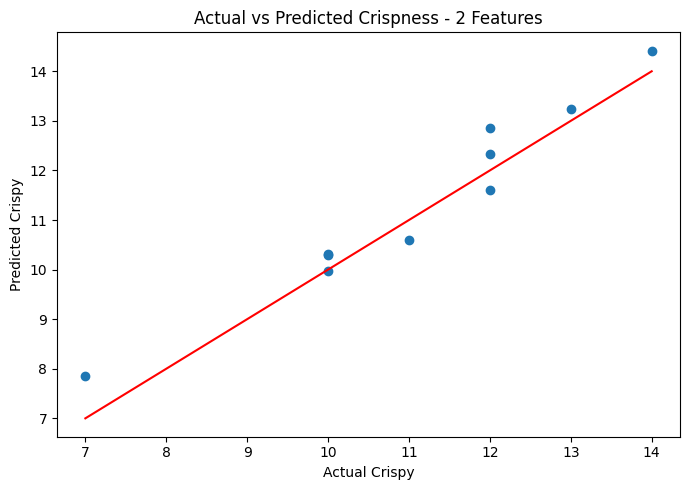

In [13]:
# Compare actual crispness values with predicted values

plt.figure(figsize=(7, 5))

plt.scatter(y2_test, y2_pred)

# Draw the reference line for perfect predictions
plt.plot(
    [y2_test.min(), y2_test.max()],
    [y2_test.min(), y2_test.max()],
    color="red"
)

plt.xlabel("Actual Crispy")
plt.ylabel("Predicted Crispy")
plt.title("Actual vs Predicted Crispness - 2 Features")

plt.tight_layout()
plt.show()

In [14]:
# Display the intercept
print("Intercept:", model2.intercept_)

# Display the coefficient of each input feature
print("\nFeature Coefficients:")

for feature, coefficient in zip(X2.columns, model2.coef_):
    print(feature, ":", round(coefficient, 4))

Intercept: 26.456145128926146

Feature Coefficients:
Fracture : -0.2285
Density : -0.0035
